In [1]:
%load_ext autoreload
%autoreload 2

In [3]:
import os
import sys
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter, MultipleLocator
import numpy as np
from tqdm import tqdm
from collections import defaultdict
from pathlib import Path
sys.path.append(str(Path.cwd().parents[0] / "src"))
from Moire_2bands import Moire
from Moire_v2 import Moire as Moire_single
import utils
import re

plt.rcParams.update({
    'figure.figsize': (6, 5),
    'figure.dpi': 120,          # crisper on screen
    'savefig.dpi': 300,         # high-res when saving
    'font.size': 12,
    'axes.titlesize': 14,
    'axes.spines.top': True,   # remove top/right borders
    'axes.spines.right': True,
    'axes.grid': False,
    'lines.linewidth': 2,
    'xtick.labelsize': 16,
    'ytick.labelsize': 16,
    "text.usetex": False,
    "mathtext.fontset": "cm",
    "font.family": "serif",
})

In [4]:
sys = Moire(theta_deg=2.0, psi_deg=26.0, V=6.6, n_shells=8)

# One Band

In [25]:
def parse_filename(name):
    pattern = re.compile(
        r"eval_MB_"
        r"(?P<grid>\d+x\d+)_"
        r"(?P<Ndn>\d+)Ndn_"
        r"(?P<Nup>\d+)Nup_"
        r"(?P<N2dn>\d+)N2dn_"
        r"(?P<N2up>\d+)N2up_"
        r"(?P<NEV>\d+)NEV(?P<Vm>\d+)_"
        r"(?P<band>\d+)b_"
        r"(?P<epsilon>\d+)0"
    )
    m = pattern.match(name)
    if not m:
        return None
    d = m.groupdict()
    # convert the purely-numeric fields to ints
    for k in ["Ndn", "Nup", "N2dn", "N2up", "NEV", "Vm", "band", "epsilon"]:
        d[k] = int(d[k])
    return d

def count_below(energies, Vm, E):
    e = energies[Vm]
    return int(np.sum(e < E))

def get_energies(path, target_epsilon):
    folder = Path(path)
    energies = defaultdict(list)

    for file in sorted(folder.rglob("eval_MB_*")):
        arr = np.atleast_2d(np.loadtxt(file))
        params = parse_filename(file.name)          # capture the return value
        if params["epsilon"] == target_epsilon:
            energies[params["Vm"]].append(arr[:, 1])

    energies = {vm: np.concatenate(arrs) for vm, arrs in energies.items()}
    energies = {vm: e - e.min() for vm, e in energies.items()}
    return energies

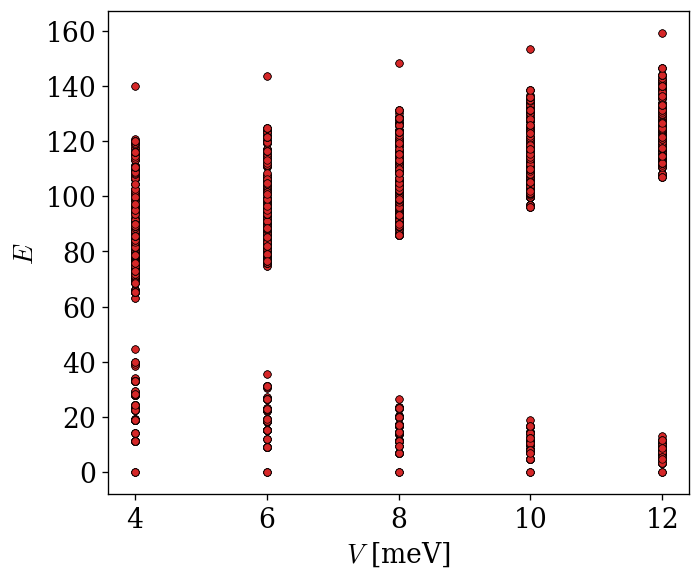

In [50]:
energies = get_energies(path="../EDDATA/ED_Results_1b", target_epsilon=5)
xs = np.concatenate([np.full(e.shape, vm) for vm, e in energies.items()])
ys = np.concatenate([e for e in energies.values()])

plt.figure()
plt.scatter(xs, ys, s=20, c="tab:red", edgecolor="k", linewidth=0.4)
plt.xlabel(r"$V$ [meV]", fontsize=16)
plt.xticks([4, 6, 8, 10, 12])
plt.ylabel(r"$E$", fontsize=16)
plt.tight_layout()
plt.show()

In [17]:
# example
count_below(energies, Vm=8, E=50.0)

256

# Two Band

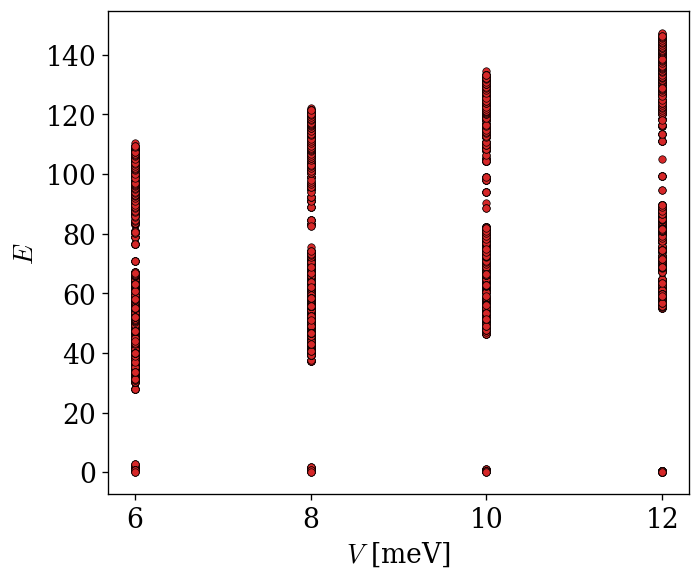

In [49]:
energies = get_energies(path="../EDDATA/ED_Results_2b", target_epsilon=5)
xs = np.concatenate([np.full(e.shape, vm) for vm, e in energies.items()])
ys = np.concatenate([e for e in energies.values()])

plt.figure()
plt.scatter(xs, ys, s=20, c="tab:red", edgecolor="k", linewidth=0.4)
plt.xlabel(r"$V$ [meV]", fontsize=16)
plt.xticks([6, 8, 10, 12])
plt.ylabel(r"$E$", fontsize=16)
plt.tight_layout()
plt.show()